# Immigration Analysis

## Lawful Immigrants
- Table 1:
    - Persons Obtaining Lawful Permanent Resident Status: 1820 to 2022
- Table 2:
    - Persons Obtaining Lawful Permanent Resident Status by **Region and Selected Country** of Last Residence: 1820 to 2022
- Table 3d:
    - Persons Obtaining Lawful Permanent Resident Status by **Region and Country of Birth**: 2013 to 2022
- Table 10d:
    - Persons Obtaining Lawful Permanent Resident Status by **Broad Class of Admission** and Region and Country of Birth: 2022

## Import Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

## Lawful Immigrants Overview (1820 - 2022)

In [2]:
# read in data
all_lawful = pd.read_excel('lawful_permanent_residents_fy2022.xlsx', sheet_name='Table 1', header=5).head(60)

### Data Cleaning
**Target**: long table with 2 columns "Year" (1820-2022) and "Number" (Immigrants)

1. Standardize data formats --> convert wide table into long table
    - **split by column, then join by row**
2. Unify column name 
3. Clean NaN
4. Correct data type ('Year' --> integer)

In [3]:
# 1. split tables --> 4 tables (2 columns / group)
'''Syntax: iloc, index locate, [:行全留，列筛选 a:b]'''
yn0 = all_lawful.iloc[:, 0:2]
yn1 = all_lawful.iloc[:, 2:4]
yn2 = all_lawful.iloc[:, 4:6]
yn3 = all_lawful.iloc[:, 6:]

# 2. unify column name (Year & Number)
'''Syntax: old_data.columns = new_name'''
yn1.columns = yn0.columns
yn2.columns = yn0.columns
yn3.columns = yn0.columns

# 1+ join tables by row
'''Syntax: pd.concat([data1, data2, data3, ...], ignore_index=True)'''
all_lawful_yn = pd.concat([yn0, yn1, yn2, yn3], ignore_index=True)

# 3. remove the last 37 rows (row 203)
all_lawful = all_lawful_yn.iloc[0:-37, :]

# 4. change data type to integer ('int')
'''Syntax: data = data.astype(new type)'''
all_lawful = all_lawful.astype(int)
all_lawful.sample(3)

,Year,Number
140,1960,265398
123,1943,23725
36,1856,200436


### Data Visualization 1

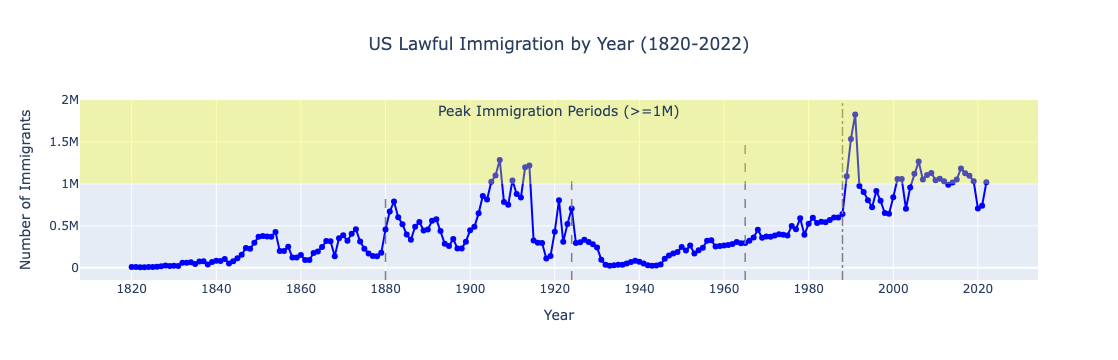

In [4]:
'''Design Line Chart to show Overall Growth across periods'''
fig1 = px.line(
    all_lawful,
    x='Year', y='Number',
    title='US Lawful Immigration by Year (1820-2022)',
    markers=True
)

# set line color
fig1.update_traces(line_color='blue')

# set details
fig1.update_layout(
    title_x=0.5,
    yaxis_title='Number of Immigrants',
    xaxis=dict(tickvals=list(range(1820, 2023, 20)))
)

fig1.add_vline(x=1880, y0=0, y1=0.5, line_dash='dash', line_color='grey', line_width=1.5)
fig1.add_vline(x=1924, y0=0, y1=0.6, line_dash='dash', line_color='grey', line_width=1.5)
fig1.add_vline(x=1965, y0=0, y1=0.8, line_dash='dash', line_color='grey', line_width=1.5)

# detected an obvious turning point at 1988
fig1.add_vline(x=1988, line_dash='dashdot', line_color='gray', line_width=1.5)

fig1.add_hrect(y0=1000000, y1=2000000, 
              fillcolor='yellow', opacity=0.3, line_width=0, 
              annotation_text="Peak Immigration Periods (>=1M)", 
              annotation_position='top', annotation_font_size=14
             )

fig1.show()

### Overview of US Immigration in 200 years
1. **Period 1**: 1820 - 1880
    - Mainly from Northern and Western Europe, primarily Ireland, Germany, and the United Kingdom. 
    - **Reason**: Fleeing the Irish Potato Famine, political upheaval, and seeking economic opportunities in northeastern factories or agricultural land. 
    
    <br>
2. **Period 2**: 1880 - 1924
    - Mainly from Southern and Eastern Europe, including Italy, Greece, Poland, and Russia. 
    - **Reason**: Escaping religious and political persecution, extreme poverty, and seeking employment in the booming industrial cities of the Midwest and Northeast.
    - **Policy**: ***Immigration Act of 1924*** established restrictive national-origin quotas and sharply limited immigration, particularly from Southern and Eastern Europe, while continuing the exclusion of Asian immigrants.

    <br>
3. **Period 3**: 1924 - 1965
    - Predominantly Latin America (especially Mexico) and Asia (including China, India, and Vietnam).
    - **Reason**: Downward from 1924 to 1945 due to WW1 and WW2, upward from 1945 to 1965 to gradually recover from the wars.
    
    <br>
4. **Period 4**: 1965 - 1988
    - Sustained upward trend, continuing the recovery phase observed in Period 3.
    - **Policy**: ***Immigration and Nationality Act of 1965***, which abolished the restrictive national-origin quotas in favor of family reunification and employment skills.

    <br>
5. **Period 5**: 1988 - 2022
    - Mainly from Vietnam with condition.
    - **Policy**: ***Amerasian Homecoming Act of 1987*** introduced in the House and enacted in December 1987, this law allowed children born in Vietnam between 1962 and 1976 to American fathers, along with their immediate family members, to immigrate to the U.S.Family.

## Lawful Immigrants by Country by Decade

In [5]:
# read in data
lawful_country=pd.read_excel('lawful_permanent_residents_fy2022.xlsx', sheet_name='Table 2', header=5)

# Extract Total & China data
'''Syntax: iloc[[想要的行数写在这], :表示所有列都保留]'''
lawful_cn_total = lawful_country.iloc[[0, 29], :]

In [6]:
lawful_cn_total

,Region and country of last residence,1820 to 1829,1830 to 1839,1840 to 1849,1850 to 1859,1860 to 1869,1870 to 1879,1880 to 1889,1890 to 1899,1900 to 1909,...,1950 to 1959,1960 to 1969,1970 to 1979,1980 to 1989,1990 to 1999,2000 to 2009,2010 to 2019,2020,2021,2022
0,Total,128502.0,538381.0,1427337.0,2814554.0,2081261.0,2742137.0,5248568.0,3694294.0,8202388.0,...,2499268.0,3213749.0,4248203.0,6244379.0,9775398.0,10299430.0,10633446.0,707362.0,740002.0,1018349.0
29,China,3.0,8.0,32.0,35933.0,54028.0,133139.0,65797.0,15268.0,19884.0,...,8836.0,14060.0,17627.0,170897.0,342058.0,591711.0,707314.0,39642.0,48072.0,62022.0


#### Data Tranformation

In [7]:
# transpose
lawful_period = lawful_cn_total.T.reset_index()

# rename the columns: 给columns重新赋值
lawful_period.columns = ['time', 'Total_immigrant', 'China_immigrant']

# drop row 0
lawful_period = lawful_period.drop(0)

'''standardize data type --> string'''
lawful_period['time'] = lawful_period['time'].astype(str)

In [8]:
lawful_period

,time,Total_immigrant,China_immigrant
1,1820 to 1829,128502.0,3.0
2,1830 to 1839,538381.0,8.0
3,1840 to 1849,1427337.0,32.0
4,1850 to 1859,2814554.0,35933.0
5,1860 to 1869,2081261.0,54028.0
6,1870 to 1879,2742137.0,133139.0
7,1880 to 1889,5248568.0,65797.0
8,1890 to 1899,3694294.0,15268.0
9,1900 to 1909,8202388.0,19884.0
10,1910 to 1919,6347380.0,20916.0


### Feature Engineering: "Decade"

- Generate new features based on calulations or conversions on existing features

In [9]:
'''Apply a manipulation to all rows in 1 column
change first 20 lines to decade; last 3 lines remain same'''
# 这里x表示的是time column里的每一个内容；对x统一进行操作-->拿出0-4再+s
lawful_period['time'][:20] = lawful_period['time'][:20].apply(lambda x: x[0:4]+'s')

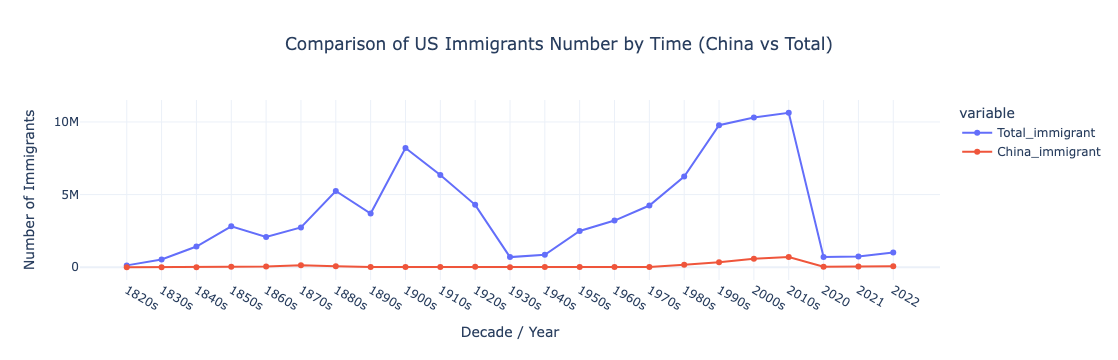

In [10]:
'''Design Line Chart to compare China and Total'''
fig2 = px.line(lawful_period, 
              # 同一个时间（共享x），对应两组数据y1,y2
              x='time', y=['Total_immigrant', 'China_immigrant'], 
              markers=True, 
              title="Comparison of US Immigrants Number by Time (China vs Total)"
             )
# 细节设置
fig2.update_layout(
    title_x = 0.5,
    xaxis_title = 'Decade / Year',
    yaxis_title = 'Number of Immigrants',
    template='plotly_white'
)

fig2.show()

### Findings: Compare China & Total Immigrants

- Increasing period 1: 1860s to 1870s
    - **Reason**: 
        - **Economic Push**: Widespread famine, extreme land scarcity, and the Punti-Makka Clan Wars in southern China
        - **Gold Rush**: The prospect of wealth, known as "Gold Mountain" in California
        - **Labor Recruitment**: Chinese laborers constructing railways until 1869, and some people decided to stay in the US together with their family members or relatives.

<br>

- Increasing period 2: 1970s to 2010s
    - **1970s**: President Nixon's visit to China in 1972
    - *1979*: **Establishment of Dipplomatic Relations between China and U.S.**   
    - **1980s**: **Ten-times increase** in Chinese immigration to U.S.
        - **Reason**: Chinese Economic Reform and Opening-up" in 1978, people get rich and more chances to go abroad.
        - Responses to encouraging policies; more official appointments abroad; the attraction of high exchange rates of US dollar and more work opportunies.
             
    - **1990s & 2000s**: **1.5 times to double growth** in Chinese immigration to U.S.
        - **Reason**: The Immigration Act of 1990 opened up significant immigration paths for highly skilled individuals and professionals, while also expanding work visa quotas (e.g. EB-1, H-1B). This period coincided with a surge of Chinese students studying abroad and a time of rapid economic growth in China.

### Feature Engineering: "CN_pct"

In [11]:
# calculate percentage: CN / Total * 100
lawful_period['CN_pct'] = lawful_period['China_immigrant']/lawful_period['Total_immigrant']*100

# change number format
lawful_period['CN_pct'] = lawful_period['CN_pct'].apply(lambda x: round(x, 4))

### Compare Trend of Number and Percent of China Immigrants

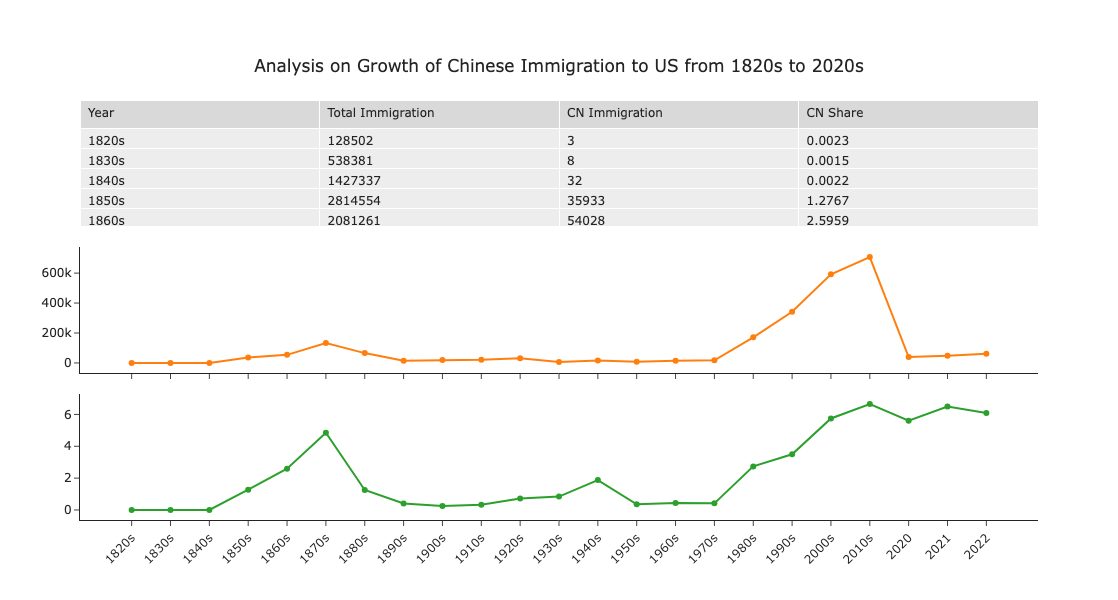

In [12]:
'''Compare Number and Percent of CN immigrants'''
fig3 = make_subplots(
    rows=3, cols=1, shared_xaxes=True,
    specs=[[{'type':'table'}], [{'type':'scatter'}], [{'type':'scatter'}]], 
    vertical_spacing=0.05

)


# add Table
fig3.add_trace(
    go.Table(
        header=dict(values=['Year', 'Total Immigration', 'CN Immigration', 'CN Share'], align='left'),
        cells=dict(values=[lawful_period[i].tolist() for i in lawful_period.columns[:]], align='left')
    ),
    row=1, col=1)


# CN immigrants
fig3.add_trace(
    go.Scatter(
        x=lawful_period['time'],
        y=lawful_period['China_immigrant'],
        mode='lines+markers',
        name='CN Count'
    ),
    row=2, col=1
)


# CN share
fig3.add_trace(
    go.Scatter(
        x=lawful_period['time'],
        y=lawful_period['CN_pct'],
        mode='lines+markers',
        name='CN Percent'
    ),
    row=3, col=1
)


fig3.update_layout(
    height=600, width=800,
    title_text='Analysis on Growth of Chinese Immigration to US from 1820s to 2020s',
    showlegend=False, 
    title_x=0.5, title_y=0.9,
    template='simple_white',
)

fig3.update_xaxes(tickangle=-45)

fig3.show()

### Findings: phase where trends in amount and percentage move in opposite direction

1. **1890s–1900s**: the total number of Chinese immigrants **increased** while the **percentage decreased**, which indicates that immigration from other countries grew faster than immigration from China.

   **Related Policy:** Chinese immigration was still restricted by a series of exclusion policies. The **Chinese Exclusion Act of 1882** suspended the immigration of Chinese laborers, the **Scott Act of 1888** restricted the reentry of Chinese residents, and the **Geary Act of 1892** extended Chinese exclusion. At the same time, the United States received a large wave of immigrants from Southern and Eastern Europe because of industrialization and the demand for labor. Therefore, Chinese immigration increased in absolute numbers, but its share decreased because total U.S. immigration increased much faster.
<br>

2. **1920s–1930s**: the total number of Chinese immigrants **decreased** while the **percentage increased**, which indicates that total immigration from other countries decreased even faster than immigration from China.

    **Related Policy:** The **Immigration Act of 1924** established restrictive national-origin quotas and excluded immigrants from Asia. Chinese exclusion policies also remained in effect. In addition, the **Great Depression** reduced employment opportunities and international migration. Therefore, the increase in the percentage of Chinese immigrants did not mean that immigration policies became more favorable toward China. It was mainly a **denominator effect**: Chinese immigration declined, but total U.S. immigration declined at an even faster rate.
<br>

3. **2021–2022**: the total number of Chinese immigrants **increased** while the **percentage decreased**, which indicates that total U.S. immigration recovered faster than immigration from China.

   **Related Policy:** This period followed the disruption caused by the **COVID-19 pandemic**. In 2021, visa processing and international travel were still affected by embassy closures, reduced capacity, and application backlogs. In 2022, visa services gradually resumed and the U.S. immigration system processed more applications across many countries and admission categories. Chinese immigration increased, but immigration from other countries increased at a faster rate. As a result, the number of Chinese immigrants rose while China's share of total U.S. immigration declined slightly.

## Lawful Immigrants by Broad Class of Admission

In [13]:
'''read in data'''
lawful_by_class = pd.read_excel('lawful_permanent_residents_fy2022.xlsx', sheet_name='Table 10d', header=5)

'''Extract Needed: Asia, China, Total, filter based on condition'''
lawful_cn_class=lawful_by_class[(lawful_by_class['Region and country of birth']=='Asia') | 
                                (lawful_by_class['Region and country of birth']=="China, People's Republic") | 
                                (lawful_by_class['Region and country of birth']=='Total')]

'''drop repeated data'''
lawful_cn_class = lawful_cn_class.drop_duplicates()
lawful_cn_class

,Region and country of birth,Total,Immediate relatives of U.S. citizens,Family-sponsored preferences,Employment-based preferences,Diversity,Refugees and asylees,Other
1,Total,1018349.0,428268,166041,270284,43233,83082,27441
3,Asia,414951.0,116745,57375,185952,17739,24156,12984
50,"China, People's Republic",67950.0,16698,11738,30514,33,8861,106


In [14]:
total_2022 = lawful_cn_class.iloc[0]['Total']
asia_2022 = lawful_cn_class.iloc[1]['Total']
cn_2022 = lawful_cn_class.iloc[2]['Total']

print('\n' + '- '*10 + 'Findings' + ' -'*10 + '\n')

print('Percent of Asian Immigrants to U.S. in 2022 is {}%.\n'.format(round(asia_2022/total_2022*100, 3)))
print('Percent of Chinese Immigrants to US in 2022 is {}%.\n'.format(round(cn_2022 /total_2022*100, 3)))
print('Percent of Chinese Immigrants of all Asian Immigrants to US in 2022 is {}%.\n'.format(round(cn_2022/asia_2022*100, 3)))


- - - - - - - - - - Findings - - - - - - - - - -

Percent of Asian Immigrants to U.S. in 2022 is 40.747%.

Percent of Chinese Immigrants to US in 2022 is 6.673%.

Percent of Chinese Immigrants of all Asian Immigrants to US in 2022 is 16.375%.



In [15]:
'''Create CN board class of admission'''
cn_2022 = lawful_by_class[(lawful_by_class['Region and country of birth']=="China, People's Republic")]
cn_by_class = cn_2022.iloc[:, 2:]
# convert data format
cn_by_class_sort = cn_by_class.T.reset_index()
cn_by_class_sort.columns=['Class', 'Amount']
cn_by_class_sorted = cn_by_class_sort.sort_values(by='Amount', ascending=False)
# cn_by_class_sorted

'''Create Total board class of admission'''
total_2022 = lawful_cn_class[(lawful_cn_class['Region and country of birth']=="Total")]
total_by_class = total_2022.iloc[:, 2:]
# convert data format
total_by_class_sort = total_by_class.T.reset_index()
total_by_class_sort.columns=['Class', 'Amount']
total_by_class_sorted = total_by_class_sort.sort_values(by='Amount', ascending=False)
total_by_class_sorted

,Class,Amount
0,Immediate relatives of U.S. citizens,428268
2,Employment-based preferences,270284
1,Family-sponsored preferences,166041
4,Refugees and asylees,83082
3,Diversity,43233
5,Other,27441


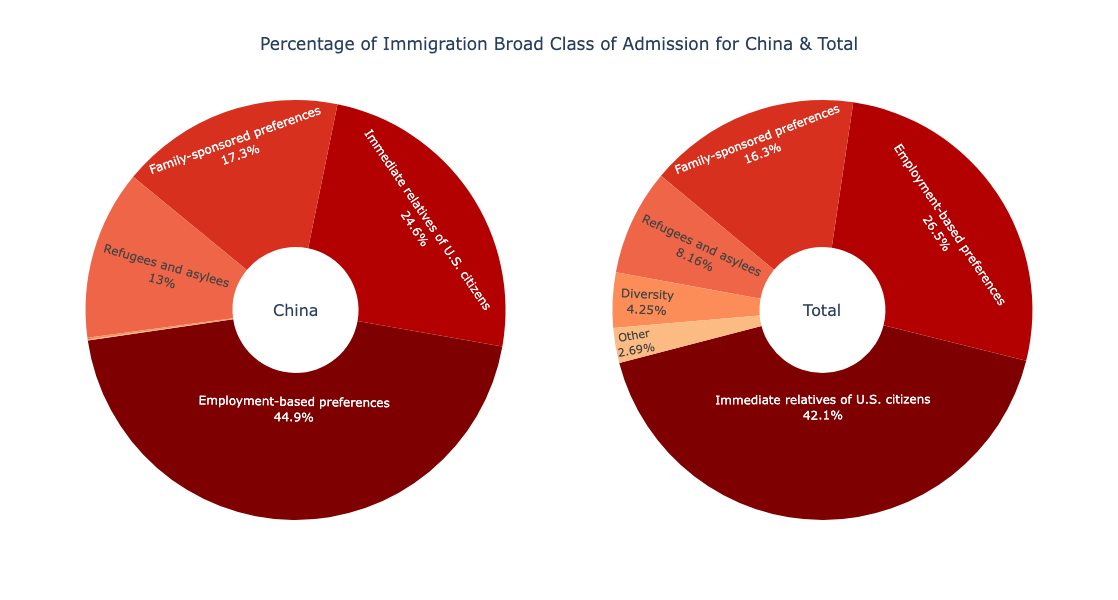

In [16]:
'''Explore the Distribution of CN Immigration Class'''
fig4 = make_subplots(
    rows=1, cols=2, shared_xaxes=True,
    specs=[[{'type':'pie'}, {'type':'pie'}]], 
    vertical_spacing=0.05)


# CN BY CLASS
fig4.add_trace(
    go.Pie(
        values=cn_by_class_sorted['Amount'], 
        labels=cn_by_class_sorted['Class'], 
        name='CN by Class',
        marker_colors = px.colors.sequential.OrRd_r,
        rotation=100,
        hole=0.3
),
    row=1, col=1)

# TOTAL BY CLASS
fig4.add_trace(
    go.Pie(
        values=total_by_class_sorted['Amount'], 
        labels=total_by_class_sorted['Class'], 
        name='Total Class',
        marker_colors = px.colors.sequential.OrRd_r,
        rotation=104,
        hole=0.3
),
    row=1, col=2)


fig4.update_traces(
    textinfo='percent+label',
    textposition='inside',
    textfont_size=12
)


fig4.update_layout(
    title_x=0.5,
    title_text='Percentage of Immigration Broad Class of Admission for China & Total',
    showlegend=False,
    width=800, height=600,
    annotations = [dict(text='China', x=sum(fig4.get_subplot(1, 1).x)/2, y=0.5, 
                        font_size=16, showarrow=False, xanchor='center'),
                   
                   dict(text='Total', x=sum(fig4.get_subplot(1, 2).x)/2, y=0.5, 
                        font_size=16, showarrow=False, xanchor='center')]

)

fig4.show()

### Findings: Broad Class of Admission — China vs Total

1. **Employment-based immigration is the largest category for China.**  
   In 2022, **Employment-based Preferences accounted for about 44.9% of Chinese lawful immigrants**, compared with about **26.5% of total U.S. lawful immigrants**. In contrast, the largest category for total U.S. immigration was **Immediate Relatives of U.S. Citizens (about 42.1%)**. This suggests that employment-based pathways play a much larger role in Chinese immigration than they do in overall U.S. immigration. Employment-based immigration includes priority workers, professionals with advanced degrees or exceptional ability, skilled workers and professionals, special immigrants, and investors. The relatively high Chinese share is consistent with the importance of professional, skilled-worker, and investment-based immigration pathways for Chinese applicants.

2. **Family-based immigration is relatively less dominant for China than for total U.S. immigration.**  
   **Immediate Relatives of U.S. Citizens accounted for about 24.6% of Chinese immigrants**, much lower than the **42.1%** share among all immigrants. Family-sponsored preferences were more similar, accounting for about **17.3% for China** and **16.3% overall**. This means that while family reunification remains an important pathway for Chinese immigrants, the Chinese immigration profile is more heavily concentrated in employment-based categories than the overall U.S. immigrant population.

3. **China has almost no Diversity Visa immigration because Chinese natives were generally not eligible for DV-2022.**  
   Diversity immigration accounted for only about **0.05% of Chinese immigrants**, compared with about **4.25% of total U.S. immigrants**. China was classified as a high-admission country and natives of China were not generally eligible for the DV-2022 program. The Diversity Visa program is designed mainly for people from countries with historically lower levels of immigration to the United States. A very small number may still appear in the China data because DV rules allow limited forms of alternate chargeability, such as using an eligible spouse's or parent's country of birth.

4. **The "Other" category is also very small for China because it contains narrow and specialized immigration pathways.**  
   The **Other** category accounted for only about **0.16% of Chinese immigrants**, compared with about **2.69% overall**. This category can include special cases such as cancellation of removal, victims of human trafficking or qualifying crimes, certain special legislation cases, children born abroad to lawful permanent residents, and some other humanitarian or special immigrant categories. These pathways apply to relatively small and specific groups, so they make up only a very small share of Chinese lawful immigration.

5. **Refugees and Asylees account for a larger share of Chinese immigration than of total U.S. immigration.**  
   Refugees and Asylees made up about **13.0% of Chinese lawful immigrants**, compared with about **8.16% of total U.S. immigrants**. China was one of the leading nationalities among people granted asylum in the United States around this period. DHS data show that Chinese nationals accounted for about **13% of all affirmative and defensive asylum grants in 2022**, making China one of the largest source countries for asylum grants. Refugees and asylees may later adjust to lawful permanent resident status after meeting the required conditions, which helps explain why this category represents a relatively larger share of Chinese lawful immigration.

### Overall Finding

Compared with total U.S. lawful immigration, Chinese immigration in 2022 was **more strongly concentrated in employment-based and refugee/asylee pathways**. **Immediate Relatives of U.S. Citizens still formed the second-largest category for Chinese immigrants, accounting for about one quarter (24.6%)**, so this pathway remained important. However, its share was lower than employment-based immigration within the Chinese immigrant population and lower than the 42.1% share among all U.S. lawful immigrants. Diversity Visa and Other categories played only very small roles. Overall, the Chinese admission profile differed substantially from the national distribution of admission categories.

## Refugees and Asylees
- Table 14d:
    - Refugee Arrivals by Region and Country of Nationality: Fiscal Years 2013 to 2022
- Table 17d:
    - Individuals Granted Asylum **Affirmatively** by Region and Country of Nationality: Fiscal Years 2013 to 2022
- Table 19d:
    - Individuals Granted Asylum **Defensively** by Region and Country of Nationality: Fiscal Years 2013 to 2022

In [17]:
# read in data
all_refugee = pd.read_excel('refugees_and_asylees_fy2022.xlsx', sheet_name='Table 14d', header=5).head(60)
refugee_cn_total = all_refugee.iloc[[1, 3, 23], :]
refugee_cn_total

,Region and country of nationality,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
1,Total,69909,69975,69920,84989.0,53691,22405,29916,11840,11454,25519
3,Asia,48756,47165,43091,48268.0,26648,7524,7852,4235,3833,9469
23,"China, People's Republic",102,57,30,57.0,27,6,D,0,0,8


In [18]:
# transpose
refugee_cn = refugee_cn_total.T.reset_index()

# rename the columns: 给columns重新赋值
refugee_cn.columns = ['Year', 'Total_refugee_by_year', 'Asian_refugee_by_year', 'China_refugee_by_year']

# drop row 0
refugee_cn = refugee_cn.drop(0)
refugee_cn
##'''standardize data type --> string'''
##lawful_period['time'] = lawful_period['time'].astype(str)

,Year,Total_refugee_by_year,Asian_refugee_by_year,China_refugee_by_year
1,2013,69909,48756,102
2,2014,69975,47165,57
3,2015,69920,43091,30
4,2016,84989.0,48268.0,57.0
5,2017,53691,26648,27
6,2018,22405,7524,6
7,2019,29916,7852,D
8,2020,11840,4235,0
9,2021,11454,3833,0
10,2022,25519,9469,8


#### Data cleaning:replace confusing value
"D": Data Withheld

In [19]:
#search by condition
D_location=np.where(refugee_cn=="D")
refugee_cn.iloc[D_location]="Data Withheld"
refugee_cn

,Year,Total_refugee_by_year,Asian_refugee_by_year,China_refugee_by_year
1,2013,69909,48756,102
2,2014,69975,47165,57
3,2015,69920,43091,30
4,2016,84989.0,48268.0,57.0
5,2017,53691,26648,27
6,2018,22405,7524,6
7,2019,29916,7852,Data Withheld
8,2020,11840,4235,0
9,2021,11454,3833,0
10,2022,25519,9469,8


### Feature Engineering: Asian_pct

In [20]:
# calculate percentage: Asian / Total * 100
refugee_cn['Asian_pct'] = refugee_cn['Asian_refugee_by_year']/refugee_cn['Total_refugee_by_year']*100

# change number format
refugee_cn['Asian_pct'] = refugee_cn['Asian_pct'].apply(lambda x: round(x, 2))
refugee_cn

,Year,Total_refugee_by_year,Asian_refugee_by_year,China_refugee_by_year,Asian_pct
1,2013,69909,48756,102,69.74
2,2014,69975,47165,57,67.40
3,2015,69920,43091,30,61.63
4,2016,84989.0,48268.0,57.0,56.79
5,2017,53691,26648,27,49.63
6,2018,22405,7524,6,33.58
7,2019,29916,7852,Data Withheld,26.25
8,2020,11840,4235,0,35.77
9,2021,11454,3833,0,33.46
10,2022,25519,9469,8,37.11


### Design a dashboard for refugee immigrants analysis

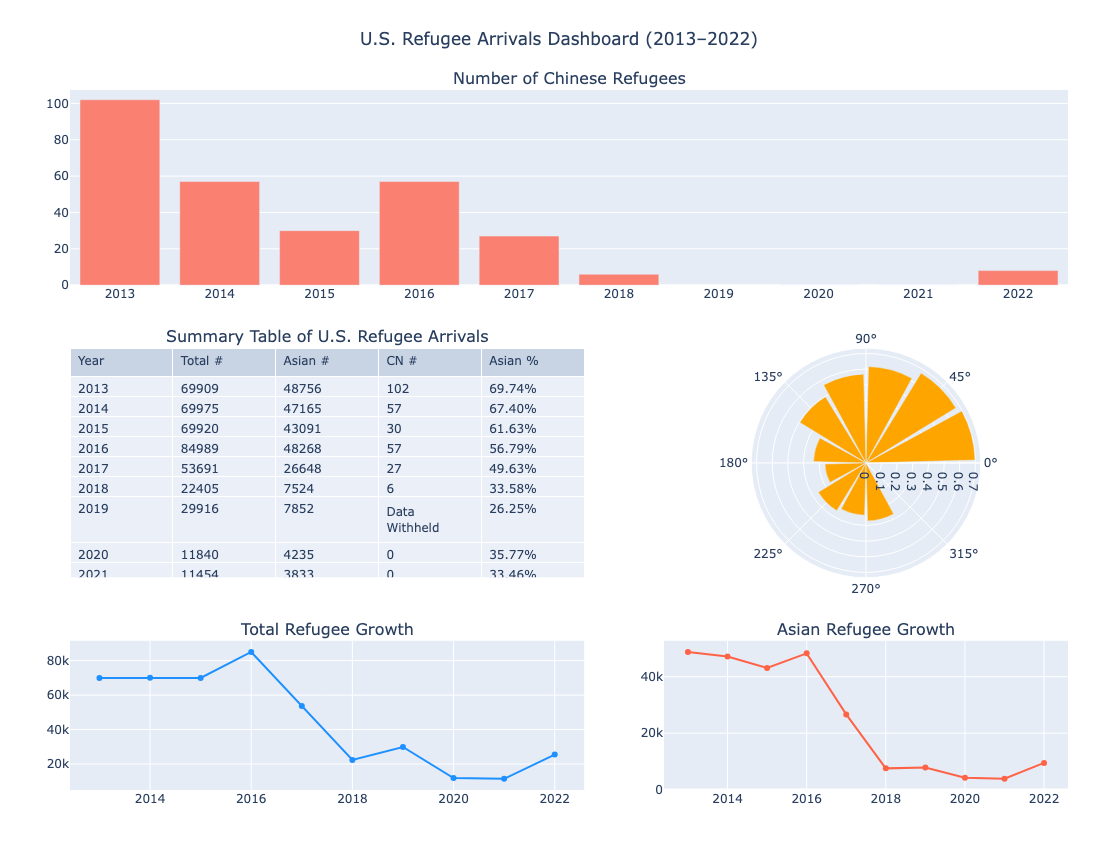

In [21]:
# Row 1: CN bar chart
# Row 2: left table; right Asian percentage
# Row 3: left total line; right Asian line

fig5 = make_subplots(
    rows=3, cols=2,
    shared_xaxes=False,
    specs=[
        [{"colspan": 2}, None],
        [{"type": "table"}, {"type": "polar"}],
        [{}, {}]
    ],
    row_heights=[0.34, 0.40, 0.26],
    column_widths=[0.56, 0.44],
    vertical_spacing=0.09,
    horizontal_spacing=0.08,
    subplot_titles=(
        "Number of Chinese Refugees",
        "Summary Table of U.S. Refugee Arrivals",
        "",
        "Total Refugee Growth",
        "Asian Refugee Growth"
    )
)

year_labels = refugee_cn["Year"].astype(str)

# 1. Number of Chinese Refugees
china_refugee_values = pd.to_numeric(
    refugee_cn["China_refugee_by_year"],
    errors="coerce"
)

fig5.add_trace(
    go.Bar(
        x=year_labels,
        y=china_refugee_values,
        name="CN Refugees",
        marker=dict(color="salmon"),
        customdata=refugee_cn["China_refugee_by_year"],
        hovertemplate=(
            "Year=%{x}<br>"
            "Chinese refugees=%{customdata}<extra></extra>"
        )
    ),
    row=1, col=1
)

# 2. Summary Table
asian_pct_labels = refugee_cn["Asian_pct"].map("{:.2f}%".format)

fig5.add_trace(
    go.Table(
        header=dict(
            values=["Year", "Total #", "Asian #", "CN #", "Asian %"],
            align="left"
        ),
        cells=dict(
            values=[
                year_labels.tolist(),
                refugee_cn["Total_refugee_by_year"].tolist(),
                refugee_cn["Asian_refugee_by_year"].tolist(),
                refugee_cn["China_refugee_by_year"].tolist(),
                asian_pct_labels.tolist()
            ],
            align="left"
        )
    ),
    row=2, col=1
)

# 3. Polar Bar Chart

fig5.add_trace(
    go.Barpolar(
        theta=list(range(15,300,30)),
        r=refugee_cn['Asian_pct']/100,
        name='Asian %',
        marker=dict(color='orange'),
    ),
    row=2, col=2
)

# 4. Total Refugee Growth

fig5.add_trace(
    go.Scatter(
        x=refugee_cn['Year'],
        y=refugee_cn['Total_refugee_by_year'],
        name='Total Refugee',
        marker=dict(color='dodgerblue'),
    ),
    row=3, col=1
)

# 5. Asian Refugee Growth

fig5.add_trace(
    go.Scatter(
        x=refugee_cn['Year'],
        y=refugee_cn['Asian_refugee_by_year'],
        name='Asian Refugee',
        marker=dict(color='tomato'),
    ),
    row=3, col=2
)

# Show every year from 2013 to 2022
fig5.update_xaxes(
    type="category",
    tickmode="array",
    tickvals=year_labels.tolist(),
    ticktext=year_labels.tolist(),
    tickangle=0,
    showticklabels=True,
    row=1, col=1
)

fig5.update_layout(
    title_x=0.5,
    title_text="U.S. Refugee Arrivals Dashboard (2013–2022)",
    showlegend=False,
    width=1050,
    height=850,
    margin=dict(l=70, r=50, t=90, b=60),
    
)

fig5.show()



### Findings

1. Chinese refugee arrivals were **relatively low**, peaking at **102 in 2013**. They declined during 2013–2015, rebounded in 2016, and fell again afterward.
   - **Policy:** Refugee admission requires **persecution-related eligibility, program access, and screening**. **Asylum is counted separately.** No separate fixed China quota was listed. The global ceiling remained **70,000 during 2013–2015**, so a lower global cap cannot explain that decline. Whether applications decreased is **unknown**.

2. Asian refugees accounted for **over 50% during 2013–2016**. Their share fell to **49.63% in 2017**, **33.58% in 2018**, and **26.25% in 2019**, then recovered to **35.77% in 2020**.
   - **Policy:** **Executive Order 13780 (2017)** sought to reduce the ceiling from **110,000 to 50,000** and suspend admissions for **120 days**, subject to court restrictions. The FY2018 ceiling fell to **45,000**, with **stricter screening**. These changes likely contributed to declining arrivals, but do not fully explain Asia's changing share.

3. Total and Asian refugee arrivals **generally followed similar trends**. Both **declined sharply from 2016 to 2018**, but increased again in **2019 and 2022**. Policy changes may help explain the decline, although the chart **cannot prove causation**.

## Individuals Granted Affirmatively & Defensively Asylums by country

In [22]:
# read in data
asylum_affirm=pd.read_excel('refugees_and_asylees_fy2022.xlsx', sheet_name='Table 17d', header=5)
asylum_defense=pd.read_excel('refugees_and_asylees_fy2022.xlsx', sheet_name='Table 19d', header=5)
#select wanted rows
asylum_affirm_cn=asylum_affirm.iloc[[1, 3, 29], :]
asylum_defense_cn=asylum_defense.iloc[[1, 3, 29], :]
#transpose to make year a variable
asylum_affirm_cn = asylum_affirm_cn.T.reset_index()
asylum_defense_cn = asylum_defense_cn.T.reset_index()
# rename the columns: 给columns重新赋值
asylum_affirm_cn.columns = ['Year', 'Total_affirm', 'Asian_affirm', 'China_affirm']
asylum_defense_cn.columns = ['Year', 'Total_defense', 'Asian_defense', 'China_defense']
# drop row 0
asylum_affirm_cn = asylum_affirm_cn.drop(0)
asylum_defense_cn = asylum_defense_cn.drop(0)
asylum_affirm_cn
asylum_defense_cn
#merge

,Year,Total_defense,Asian_defense,China_defense
1,2013,9745,6091,4521
2,2014,8614,5385,3970
3,2015,8139,4768,3584
4,2016,8695,4218,3078
5,2017,10565,4251,2731
6,2018,13198,5655,3049
7,2019,18912,7686,3459
8,2020,14604,4671,1950
9,2021,7416,2262,782
10,2022,22481,8313,3051


In [23]:
# Merge affirmative and defensive asylum data by year
asylum = pd.merge(
    asylum_affirm_cn,
    asylum_defense_cn,
    on='Year',
    how='left'
)

asylum

,Year,Total_affirm,Asian_affirm,China_affirm,Total_defense,Asian_defense,China_defense
0,2013,14886,7392,4005,9745,6091,4521
1,2014,14424,7409,3896,8614,5385,3970
2,2015,17807,6570,2592,8139,4768,3584
3,2016,11616,4367,1410,8695,4218,3078
4,2017,15817,5715,2825,10565,4251,2731
5,2018,24504,7878,3760,13198,5655,3049
6,2019,26893,9230,3955,18912,7686,3459
7,2020,16132,6332,2799,14604,4671,1950
8,2021,9212,3295,1088,7416,2262,782
9,2022,14134,5951,1538,22481,8313,3051


### Feature Engineering
'Total_asylum', 'Asian_asylum', 'China_asylum'

In [24]:
asylum['Total Asylum']=asylum['Total_affirm'] + asylum['Total_defense']
asylum['Asian_asylum']=asylum['Asian_affirm'] + asylum['Asian_defense']
asylum['China_asylum']=asylum['China_affirm'] + asylum['China_defense']

#reorder the table
cols=asylum.columns.tolist()
cols_ord=['Year']+cols[1:10:3]+cols[2:10:3]+cols[3:10:3]
asylum=asylum[cols_ord]
asylum

,Year,Total_affirm,Total_defense,Total Asylum,Asian_affirm,Asian_defense,Asian_asylum,China_affirm,China_defense,China_asylum
0,2013,14886,9745,24631,7392,6091,13483,4005,4521,8526
1,2014,14424,8614,23038,7409,5385,12794,3896,3970,7866
2,2015,17807,8139,25946,6570,4768,11338,2592,3584,6176
3,2016,11616,8695,20311,4367,4218,8585,1410,3078,4488
4,2017,15817,10565,26382,5715,4251,9966,2825,2731,5556
5,2018,24504,13198,37702,7878,5655,13533,3760,3049,6809
6,2019,26893,18912,45805,9230,7686,16916,3955,3459,7414
7,2020,16132,14604,30736,6332,4671,11003,2799,1950,4749
8,2021,9212,7416,16628,3295,2262,5557,1088,782,1870
9,2022,14134,22481,36615,5951,8313,14264,1538,3051,4589


### Total asylums to US by status (affirmative vs defensive)

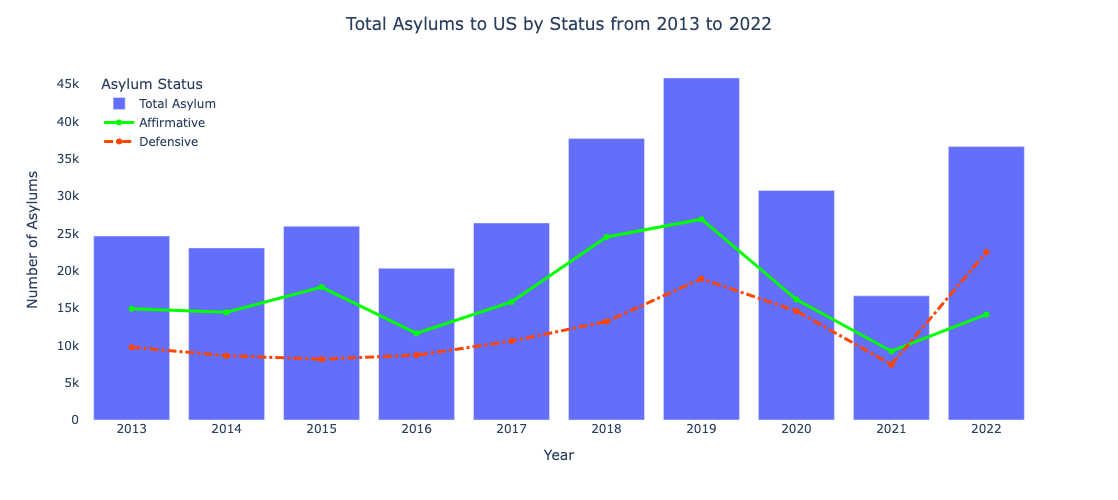

In [25]:
asylum=asylum.astype(int)
fig6=px.bar(
    asylum,
    x='Year',
    y=['Total Asylum'],
    labels={'variable':'Asylum Status'}
)

#lable affirmative trend
fig6.add_trace(
    go.Scatter(
        x=asylum['Year'],
        y=asylum['Total_affirm'],
        mode='lines+markers',
        name='Affirmative',
        line=dict(color='lime',width=3),
        marker=dict(size=6)
    )
)

#lable defensive trend
fig6.add_trace(
    go.Scatter(
        x=asylum['Year'],
        y=asylum['Total_defense'],
        mode='lines+markers',
        name='Defensive',
        line=dict(color='orangered',width=3,dash='dashdot'),
        marker=dict(size=6)
    )
)
fig6.update_layout(
    title_x=0.5,
    title_text='Total Asylums to US by Status from 2013 to 2022',
    width=800, height=500,
    xaxis=dict(tickvals=list(range(2013,2023,1))),
    yaxis_title='Number of Asylums',
    legend=dict(xanchor='left',x=0.02,yanchor='top',y=0.97,orientation='v'),
    plot_bgcolor='white'
)
fig6.show()

### Findings
1. From 2013 to 2017, the growth of total asylums to US remain stable. However, from 2018 to 2019, **a significant increase** can be detected.
   - policy: In 2018, USCIS returned to the **Last In, First Out (LIFO)** policy for affirmative asylum interviews. Newer applications were generally scheduled before older cases, which changed the processing order of affirmative asylum cases.


2. From 2020 to 2021, the growth of asylums **decreased**, reaching a 10-year low due to COVID-19. In 2022, it returned to the levels close to that of 2018.
   - policy: During COVID-19 in 2020, USCIS temporarily suspended routine in-person services at asylum offices, while many immigration court hearings were also postponed. This affected both **affirmative asylum interviews** and **defensive asylum hearings**.


3. By comparing between Affirmative and Defensive groups, we noticed that the **amount of Affirmative asylums is always more than that of Defensive asylums**, except in 2022.
   - policy:In 2021, DHS and DOJ created the **Dedicated Docket** for certain families in removal proceedings. Immigration judges were expected to make decisions more quickly, generally within about 300 days, which increased the speed of processing some defensive asylum cases.


4. The Affirmative group experienced relatively drastic fluctuations over the 10-year period, while the Defensive group showed a relatively smooth trend.

### Chinese asylums to US by status (affirmative vs defensive)

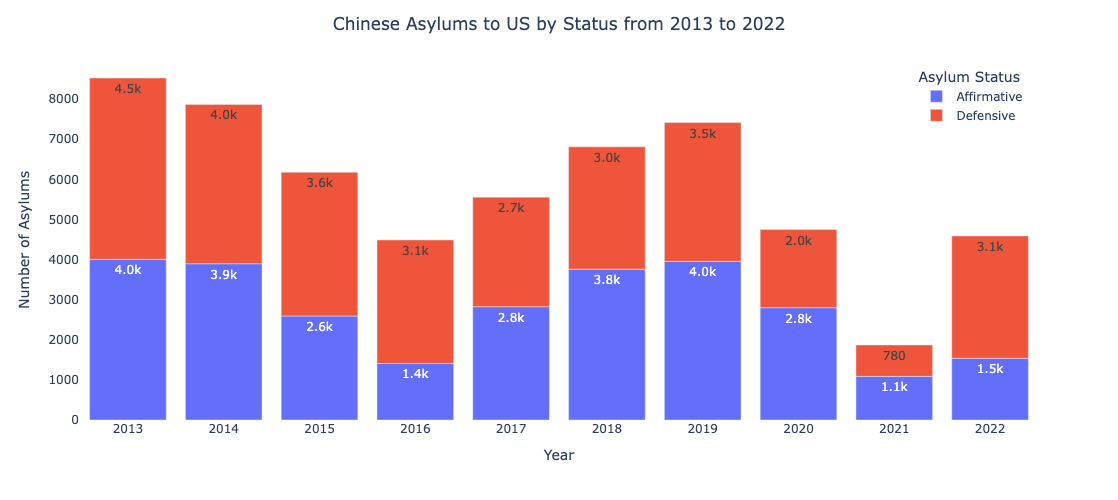

In [26]:
fig7=px.bar(
    asylum,
    x='Year',
    y=['China_affirm','China_defense'],
    labels={'variable':'Asylum Status'},
    text_auto='.2s'
)

fig7.update_layout(
    title_x=0.5,
    title_text='Chinese Asylums to US by Status from 2013 to 2022',
    width=800, height=500,
    xaxis=dict(tickvals=list(range(2013,2023,1))),
    yaxis_title='Number of Asylums',
    legend=dict(xanchor='right',x=0.99,yanchor='top',y=0.99,orientation='v'),
    plot_bgcolor='white'
)
fig7.update_traces(selector=dict(name='China_affirm'),name='Affirmative')
fig7.update_traces(selector=dict(name='China_defense'),name='Defensive')
fig7.show()

### Findings

1. **Overall trend:** From 2013 to 2016, the total number of Chinese asylums decreased by approximately 50%. It then rebounded from 2017 to 2019, but did not return to the earlier peak. From 2020 to 2021, the number decreased significantly and reached the lowest level of the decade. In 2022, it recovered to a level slightly higher than 2016.

2. **Comparison between Affirmative and Defensive groups:** From 2013 to 2016, the number of Defensive asylums was higher than Affirmative asylums. From 2017 to 2021, Affirmative asylums became higher than Defensive asylums. In 2022, Defensive asylums became higher again. Therefore, China was different from the overall U.S. trend mainly during 2013–2016.

3. **Background Research: Chinese Asylums Reach the Trough Value in 2016.**

   In this dataset, Chinese asylum grants decreased to 4488 in 2016. An important event related to Chinese asylum claims during this period was the **"709 Crackdown"** that began in July 2015. The Chinese government detained or questioned more than 300 human-rights lawyers, legal workers, and activists. The U.S. Department of State also reported increased pressure on civil-rights advocates and the legal community during this period. These events may have contributed to persecution-related asylum claims by some Chinese applicants.

   However, the asylum data alone cannot prove that the crackdown directly caused changes in the number of asylum grants. It is also important to distinguish between **applications and grants**. The DHS data used in this analysis report people who were granted asylum. A Defensive asylum application is filed in immigration court by a person who is already in removal proceedings.

### Asian asylums to US by status (affirmative vs defensive)

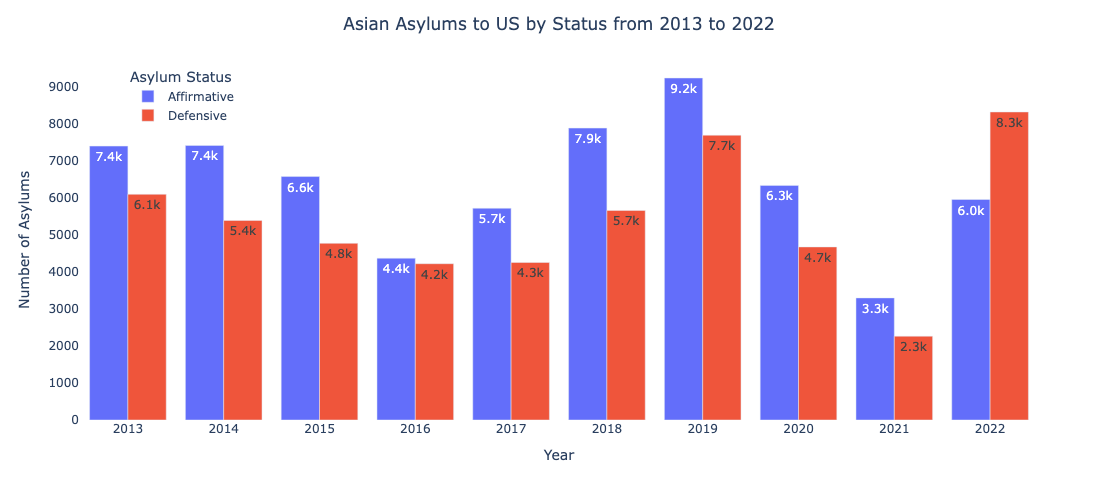

In [27]:
fig8=px.bar(
    asylum,
    x='Year',
    y=['Asian_affirm','Asian_defense'],
    labels={'variable':'Asylum Status'},
    text_auto='.2s'
)

fig8.update_layout(
    title_x=0.5,
    title_text='Asian Asylums to US by Status from 2013 to 2022',
    width=800, height=500,
    xaxis=dict(tickvals=list(range(2013,2023,1))),
    yaxis_title='Number of Asylums',
    legend=dict(xanchor='left',x=0.05,yanchor='top',y=0.99,orientation='v'),
    plot_bgcolor='white',
    barmode='group'
)
fig8.update_traces(selector=dict(name='Asian_affirm'),name='Affirmative')
fig8.update_traces(selector=dict(name='Asian_defense'),name='Defensive')

fig8.show()

### Findings
- By comparing the Affirmative and Defensive groups in Asia, we notice that Affirmative asylums were higher than Defensive asylums from 2013 to 2021. In 2022, Defensive asylums became higher than Affirmative asylums. This pattern is consistent with the overall trend of total asylums to the U.S.

### Design a polar bar to compare asylum growth in CN and Asian

In [28]:
#upper right: CN affirm
cn_aff=asylum[['Year','China_affirm']]
cn_aff.insert(0,'theta',list(range(5,90,9)))
cn_aff['Type']='CN Affirmative'
cn_aff=cn_aff.rename(columns={'China_affirm':'Amount'})

#lower right: Asian defense
as_def=asylum[['Year','Asian_defense']]
as_def.insert(0,'theta',list(range(95,180,9)))
as_def['Type']='Asian Defensive'
as_def=as_def.rename(columns={'Asian_defense':'Amount'})

#lower left: CN defense
cn_def=asylum[['Year','China_defense']]
cn_def.insert(0,'theta',list(range(185,270,9)))
cn_def['Type']='CN Defensive'
cn_def=cn_def.rename(columns={'China_defense':'Amount'})

#upper left: Asian affirm
as_aff=asylum[['Year','Asian_affirm']]
as_aff.insert(0,'theta',list(range(275,360,9)))
as_aff['Type']='Asian Affirmative'
as_aff=as_aff.rename(columns={'Asian_affirm':'Amount'})

#merge four parts into one data frame
polar_data=pd.concat([cn_aff,as_def,cn_def,as_aff],axis=0,ignore_index=True)

fig9=px.bar_polar(
    polar_data,
    r='Amount',
    theta='theta',
    color='Type',
    hover_data='Year',
    title='Polar Bar to Compare Asylum Growth in CN and Asian(2013-2022)',
    color_discrete_sequence=['blueviolet','lightsalmon','mediumpurple','tomato'],
)

fig9.update_layout(
    width=750,
    height=600,
    legend=dict(xanchor='left',x=0.05,yanchor='bottom',y=-0.2,orientation='h'),
)

fig9.show()

### Findings

#### Affirmative Comparison
1. **China and Asia show a similar overall trend in the affirmative group.** Both decreased from 2013 to 2016, increased from 2017 to 2019, dropped sharply from 2020 to 2021, and recovered in 2022. This suggests that China and Asia were affected by some common factors over this period.

2. **However, the recovery in Asia was stronger than in China.** Asian affirmative asylums increased much more strongly from 2017 to 2019 and reached their highest level in 2019. Chinese affirmative asylums also increased, but they did not return to their earlier peak.

3. **China's share of Asian affirmative asylums continuously decreased over time.** In 2013, Chinese affirmative asylums accounted for about 54.1% of all Asian affirmative asylums, but this decreased to about 25.8% in 2022. This indicates that affirmative asylum growth in Asia increasingly came from countries other than China.

#### Defensive Comparison
1. **China and Asia also show a similar overall trend in the defensive group.** Both decreased from 2013 to 2016, increased from 2018 to 2019, dropped sharply from 2020 to 2021, and recovered in 2022. This shows that all Asian countries including China are affected by similar factors or policies.

2. **The period with diffenrent trends is 2016 to 2017**, during which Asian defensive asylums began to increase in 2017, while Chinese defensive asylums continued its downward trend.

3. **China's share of Asian defensive asylums also decreased from 2013 to 2021, but rebounded in 2022.** In 2013, Chinese defensive asylums accounted for about 74.2% of all Asian defensive asylums, and it reaches its lowest percentage of 34.5%, but it recovered to about 36.7% in 2022. China has consistently been a key contributor of defensive asylums among Asian countries, with its influence on the number of defensive asylums surpassing its influence on the number of affirmative asylums.

**Conclusion**: China and Asia followed a similar direction of change in the number of asylums, but China's relative importance within Asian asylum cases decreased during the ten-year period.

# Technical Summary

## Data Collection
- Description:
  - Part 1: Lawful immigrants
  - Part 2: Refugees and Asylums
- Data Source:
  - **Office of Homeland Security Statistics**(Yearbook 2022 of Immigration)
  - Citation Link: https://ohss.dhs.gov/topics/immigration/yearbook

## Exploratory Data Analysis & Data Cleaning
1. **Standardized data formats** by converting wide tables into long tables.
2. **Cleaned missing values, replaced confusing values with specific meanings** (such as replacing "D" with "Data Withheld"), and **corrected data types**.
3. **Performed data transformation by transposing tables, reseting index, and unifying columns.**
4. **Feature Engineering:** Generated new features "Dacade", "CN_pct", and "Asian_pct" based on calculations on other existing features, to further explore the immigration trends by dacade and **detect the changes in percentage** of Chinese immigrants and Asian immigrants to US, while **identifing the existence of both positive and negative target immigration policies against China**. Calculated new features "Total_asylum", "Asian_asylum", and "China_asylum" to refine the dataset and conduct in-depth analysis of asylum immigrants.

## Data Visualization
### Part 1: Lawful immigrants
1. US Lawful Immigration by Year (1820-2022)
   - Designed an **Interactive Line Chart using Plotly** to show the **overall growth** of lawful immigration to US across periods.
   - Based on the **research on Three Immigration Waves in US history**, we explored the **reasons and corresponding immigration policies** for each period, as well as **self-defined two Immigration Periods** after 1965 <u/>based on data visualization of the growth trend of immigrant numbers</u>.
2. Generated Line Chart to compare the number of US Immigrants by Year in the past decade 2013-2022 (China vs Total).
3. Plotted Interactive **Pie Chart** to show the Percentage of each Immigration Broad Class of Admission for Chinese immigrant and Total immigrants to US.

### Part 2: Refugees and Asylums
1. Designed a **Comprehensive Interactive Dashboard using Plotly** to analyze Refugee Arrivals in US from 2013 to 2022, incorporating **Bar Chart** to show numbers of refugees over years, **Polar Bar** to show percentage growth of Chinese refugees, **Line Charts** to show growth trends, and a **Summary Table** to compare among countries or regions.
2. Created a **Bar Chart** to display number of total asylums to US by status, and **added Line Charts to compare between affirmative and defensive groups**.
3. Applied **Stacked Bar Chart** and **Grouped Bar Chart** to compare Chinese asylums to US total asylums by status.
4. Plotted an **Interactive Polar Bar** to compare asylum growth **by status from both China and Asia in total**.